In [4]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

Config 1: Mean = 0.8577, Std = 0.0130, 95% CI = [0.8254, 0.8900]
Config 2: Mean = 0.8576, Std = 0.0140, 95% CI = [0.8228, 0.8924]
Config 3: Mean = 0.8569, Std = 0.0200, 95% CI = [0.8072, 0.9066]
Config 4: Mean = 0.8569, Std = 0.0200, 95% CI = [0.8072, 0.9066]


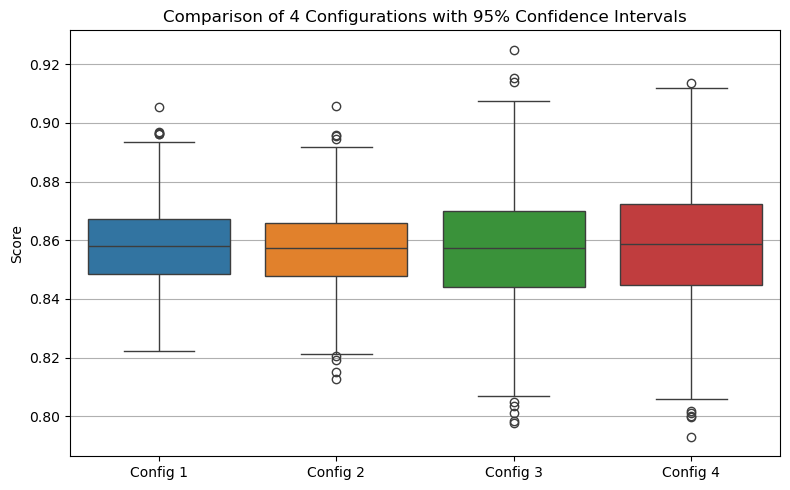

In [5]:
# === Input: mean and std for each config ===
means = [0.8577,0.8576,0.8569,0.8569]
stds  = [0.013,0.014,0.020,0.020]

# Assume n = 3 folds
n = 3

# Prepare data and print 95% CIs
simulated_data = []
labels = []

for i in range(len(means)):
    mean = means[i]
    std = stds[i]
    
    # 95% CI: mean ± t * (std / sqrt(n))
    sem = std / np.sqrt(n)
    t_value = stats.t.ppf(0.975, df=n-1)
    ci_lower = mean - t_value * sem
    ci_upper = mean + t_value * sem
    
    print(f"Config {i+1}: Mean = {mean:.4f}, Std = {std:.4f}, 95% CI = [{ci_lower:.4f}, {ci_upper:.4f}]")
    
    # Simulate n points for boxplot
    simulated_points = np.random.normal(loc=mean, scale=std, size=1000)
    simulated_data.append(simulated_points)
    labels.append(f'Config {i+1}')

# === Plot boxplots ===
plt.figure(figsize=(8, 5))
sns.boxplot(data=simulated_data)
plt.xticks(ticks=np.arange(len(labels)), labels=labels)
plt.ylabel('Score')
plt.title('Comparison of 4 Configurations with 95% Confidence Intervals')
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

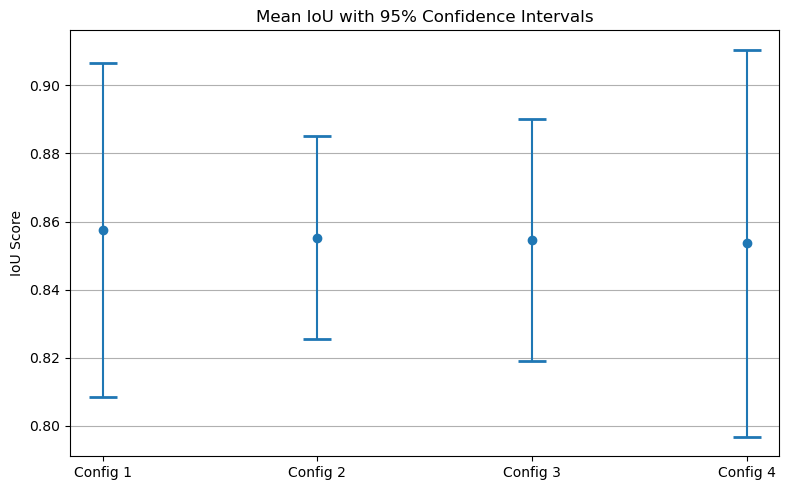

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

means = np.array([0.8575,0.8553,0.8546,0.8536])
stds  = np.array([0.0198,0.0120,0.0143,0.0229])
n = 3

# Calculate 95% CI
sem = stds / np.sqrt(n)
t_value = stats.t.ppf(0.975, df=n-1)
ci_half_width = t_value * sem

# Plot
labels = [f'Config {i+1}' for i in range(len(means))]
x_pos = np.arange(len(means))

plt.figure(figsize=(8,5))
plt.errorbar(x_pos, means, yerr=ci_half_width, fmt='o', capsize=10, capthick=2)
plt.xticks(x_pos, labels)
plt.ylabel('IoU Score')
plt.title('Mean IoU with 95% Confidence Intervals')
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

In [13]:
#Friedman test
import numpy as np
from scipy.stats import friedmanchisquare

# Example: load fold1 per-image IOUs
fold = 1

# Load per-image IoU arrays for this fold
iou_dino      = np.load(f"exports/unet/dino_np/per_image_iou_fold{fold}_dino.npy")
iou_resnet50  = np.load(f"exports/unet/resnet_np/per_image_iou_fold{fold}.npy")
iou_baseline  = np.load(f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy")

# Make sure they have the same length (same images)
assert len(iou_dino) == len(iou_resnet50) == len(iou_baseline), "Mismatch in number of images!"

# Run Friedman test
statistic, p_value = friedmanchisquare(iou_dino, iou_resnet50, iou_baseline)

# Print results
print(f"Friedman test statistic: {statistic:.4f}, p-value: {p_value:.4f}")

# Interpret
alpha = 0.05
if p_value < alpha:
    print("→ Significant differences between models (reject H0)")
else:
    print("→ No significant differences between models (fail to reject H0)")

Friedman test statistic: 8.6286, p-value: 0.0134
→ Significant differences between models (reject H0)


In [12]:
import numpy as np
import scikit_posthocs as sp
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize lists to gather all IoUs across all folds
all_iou_dino = []
all_iou_resnet = []
all_iou_baseline = []

# Loop over all 5 folds
for fold in range(1, 6):
    iou_dino      = np.load(f"exports/unet/dino_np/per_image_iou_fold{fold}_dino.npy")
    iou_resnet50  = np.load(f"exports/unet/resnet_np/per_image_iou_fold{fold}.npy")
    iou_baseline  = np.load(f"exports/baseline/baseline_np/per_image_iou_fold{fold}_baseline.npy")

    # Ensure consistency
    assert len(iou_dino) == len(iou_resnet50) == len(iou_baseline), f"Mismatch in fold {fold}"

    # Extend lists
    all_iou_dino.extend(iou_dino)
    all_iou_resnet.extend(iou_resnet50)
    all_iou_baseline.extend(iou_baseline)

# Stack into shape (num_samples, 3)
data = np.vstack([all_iou_dino, all_iou_resnet, all_iou_baseline]).T

# Run the Nemenyi test
nemenyi_result = sp.posthoc_nemenyi_friedman(data)

# Print result
print("Combined Nemenyi post-hoc test (p-values):")
print(nemenyi_result)


AssertionError: Mismatch in fold 2